# Book Recommender System using a Medallion Data Lake (Bronze → Silver → Gold)
**Dataset:** Book-Crossing (Users, Books, Book-Ratings)
**Method:** Item-based collaborative filtering (cosine similarity, `NearestNeighbors`)

Pipeline: raw CSV → **Bronze** (untouched copy, Parquet) → **Silver** (cleaned) → **Gold** (model-ready) → recommender.

## Step 1: Set up the data lake and build the Bronze layer

In [1]:
import os, string, zipfile, urllib.request
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from datetime import datetime, timezone

# Create the data lake folders
for folder in ["bronze", "silver", "gold"]:
    os.makedirs(folder, exist_ok=True)

# Download the raw files (skipped if they are already present)
URL = "https://cdn.freecodecamp.org/project-data/books/book-crossings.zip"
RAW_FILES = ["BX-Books.csv", "BX-Users.csv", "BX-Book-Ratings.csv"]
if not all(os.path.exists(f) for f in RAW_FILES):
    urllib.request.urlretrieve(URL, "book-crossings.zip")
    with zipfile.ZipFile("book-crossings.zip") as z:
        z.extractall(".")
print([f for f in os.listdir(".") if f.endswith(".csv")])

['BX-Book-Ratings.csv', 'BX-Books.csv', 'BX-Users.csv']


In [2]:
# Load exactly as-is: ';' separator, latin-1 encoding (files are not UTF-8),
# every column kept as a string so nothing is converted or cleaned.
read_opts = dict(sep=";", encoding="latin-1", dtype=str,
                 quotechar='"', escapechar="\\")  # some titles contain \" escaped quotes

books_raw   = pd.read_csv("BX-Books.csv", **read_opts)
users_raw   = pd.read_csv("BX-Users.csv", **read_opts)
ratings_raw = pd.read_csv("BX-Book-Ratings.csv", **read_opts)

ts = datetime.now(timezone.utc).isoformat()
for name, df in [("books", books_raw), ("users", users_raw), ("ratings", ratings_raw)]:
    df["ingestion_timestamp"] = ts
    df.to_parquet(f"bronze/{name}.parquet", index=False)
    print(f"bronze/{name}.parquet  ->  {df.shape}")

bronze/books.parquet  ->  (271379, 9)
bronze/users.parquet  ->  (278858, 4)


bronze/ratings.parquet  ->  (1149780, 4)


## Step 2: Explore the Bronze data (EDA)

In [3]:
books   = pd.read_parquet("bronze/books.parquet")
users   = pd.read_parquet("bronze/users.parquet")
ratings = pd.read_parquet("bronze/ratings.parquet")

for name, df in [("books", books), ("users", users), ("ratings", ratings)]:
    print(f"===== {name}: shape {df.shape} =====")
    print(pd.DataFrame({"dtype": df.dtypes, "missing": df.isna().sum(),
                        "duplicates_in_table": df.duplicated().sum()}))
    print()

===== books: shape (271379, 9) =====
                      dtype  missing  duplicates_in_table
ISBN                 object        0                    0
Book-Title           object        0                    0
Book-Author          object        2                    0
Year-Of-Publication  object        0                    0
Publisher            object        2                    0
Image-URL-S          object        0                    0
Image-URL-M          object        0                    0
Image-URL-L          object        0                    0
ingestion_timestamp  object        0                    0

===== users: shape (278858, 4) =====


                      dtype  missing  duplicates_in_table
User-ID              object        0                    0
Location             object        0                    0
Age                  object   110762                    0
ingestion_timestamp  object        0                    0

===== ratings: shape (1149780, 4) =====
                      dtype  missing  duplicates_in_table
User-ID              object        0                    0
ISBN                 object        0                    0
Book-Rating          object        0                    0
ingestion_timestamp  object        0                    0



**Finding (shape/types/missing):** Books 271,379 × 9, Users 278,858 × 4, Ratings 1,149,780 × 4. Everything is loaded as text (object). Users.Age has ~110k missing values ("NULL"), Books has 2 missing authors and 2 missing publishers. **Silver action:** cast Age, Year and Rating to numbers, fill Age with the median, and drop duplicates.

Book-Rating
0     716109
1       1770
2       2759
3       5996
4       8904
5      50974
6      36924
7      76457
8     103736
9      67541
10     78610
Name: count, dtype: int64



Share of 0 ratings: 62.3%


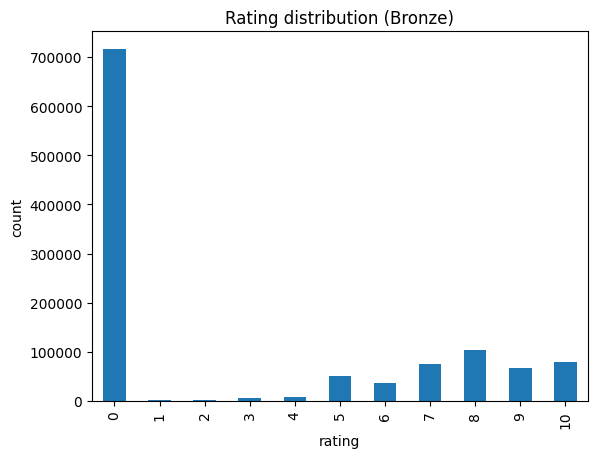

In [4]:
r = pd.to_numeric(ratings["Book-Rating"])
counts = r.value_counts().sort_index()
print(counts)
print(f"\nShare of 0 ratings: {(r == 0).mean():.1%}")
counts.plot(kind="bar", title="Rating distribution (Bronze)", xlabel="rating", ylabel="count")
plt.show()

**Finding (ratings):** 716,109 of 1,149,780 ratings (**62%**) are 0, which means "implicit / no explicit rating". The explicit 1–10 ratings lean towards high scores (8 is the most common). **Silver action:** drop all 0 ratings and keep only 1–10.

count    168096.000000
mean         34.751434
std          14.428097
min           0.000000
25%          24.000000
50%          32.000000
75%          44.000000
max         244.000000
Name: Age, dtype: float64
ages < 5: 882 | ages > 100: 366 | missing: 110762

count    271379.000000
mean       1959.756050
std         258.011363
min           0.000000
25%        1989.000000
50%        1995.000000
75%        2000.000000
max        2050.000000
Name: Year-Of-Publication, dtype: float64
year == 0: 4619 | year in the future: 11


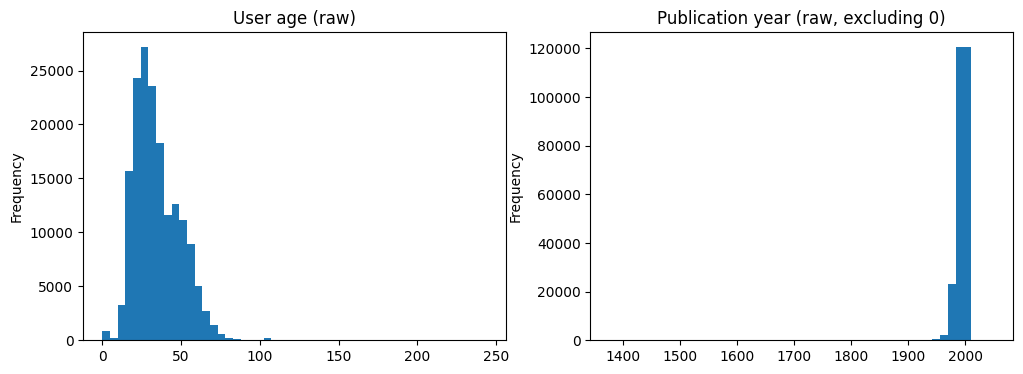

In [5]:
age  = pd.to_numeric(users["Age"], errors="coerce")
year = pd.to_numeric(books["Year-Of-Publication"], errors="coerce")
print(age.describe())
print("ages < 5:", (age < 5).sum(), "| ages > 100:", (age > 100).sum(), "| missing:", age.isna().sum())
print()
print(year.describe())
print("year == 0:", (year == 0).sum(), "| year in the future:", (year > datetime.now().year).sum())

fig, ax = plt.subplots(1, 2, figsize=(12, 4))
age.plot(kind="hist", bins=50, ax=ax[0], title="User age (raw)")
year[year > 0].plot(kind="hist", bins=50, ax=ax[1], title="Publication year (raw, excluding 0)")
plt.show()

**Finding (age):** Ages range from 0 to 244. 882 users are under 5 and 366 are over 100, which is impossible. **Silver action:** set ages <5 or >100 to null, then fill all nulls with the median age.

**Finding (year):** 4,619 books have year 0 and 11 have years in the future (up to 2050). **Silver action:** set both to null.

Ratings per user:
 count    77805.000000
mean         5.573819
std         44.001879
min          1.000000
25%          1.000000
50%          1.000000
75%          3.000000
max       8524.000000
dtype: float64 

Ratings per book:
 count    185973.000000
mean          2.331903
std           6.834667
min           1.000000
25%           1.000000
50%           1.000000
75%           2.000000
max         707.000000
dtype: float64 

>=  1 ratings:  77805 users | 185973 books
>=  5 ratings:  14220 users |  14535 books
>= 10 ratings:   7334 users |   5645 books
>= 20 ratings:   3704 users |   2179 books
>= 50 ratings:   1332 users |    537 books


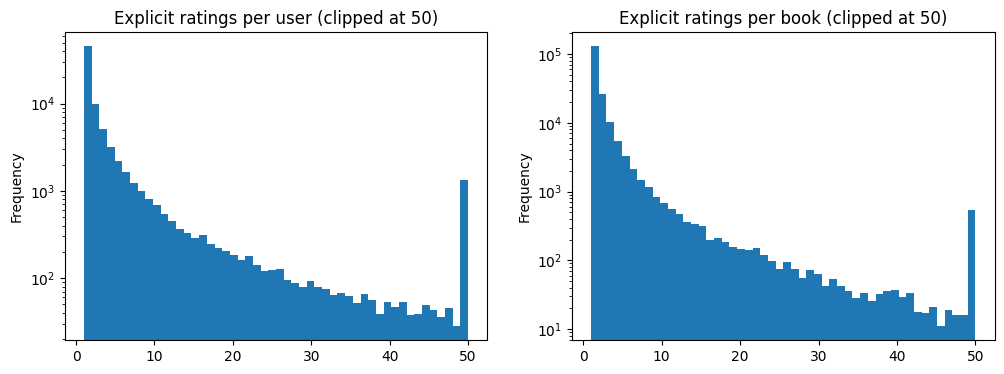

In [6]:
explicit = ratings[pd.to_numeric(ratings["Book-Rating"]) > 0]
per_user = explicit.groupby("User-ID").size()
per_book = explicit.groupby("ISBN").size()
print("Ratings per user:\n", per_user.describe(), "\n")
print("Ratings per book:\n", per_book.describe(), "\n")
for k in [1, 5, 10, 20, 50]:
    print(f">= {k:>2} ratings: {(per_user >= k).sum():>6} users | {(per_book >= k).sum():>6} books")

fig, ax = plt.subplots(1, 2, figsize=(12, 4))
per_user.clip(upper=50).plot(kind="hist", bins=50, ax=ax[0], log=True, title="Explicit ratings per user (clipped at 50)")
per_book.clip(upper=50).plot(kind="hist", bins=50, ax=ax[1], log=True, title="Explicit ratings per book (clipped at 50)")
plt.show()

**Finding (activity):** The median user and the median book each have just **1** explicit rating (long tail). Only ~7.3k users and ~5.6k books have 10 or more. **Silver action:** keep only users and books with at least a minimum number of ratings, so similarities are based on real overlap.

In [7]:
n_users, n_books = ratings["User-ID"].nunique(), ratings["ISBN"].nunique()
sparsity_all = len(ratings) / (n_users * n_books) * 100
sparsity_exp = len(explicit) / (explicit["User-ID"].nunique() * explicit["ISBN"].nunique()) * 100
print(f"All ratings:      {len(ratings):,} / ({n_users:,} users x {n_books:,} books) = {sparsity_all:.4f}% filled")
print(f"Explicit ratings: {sparsity_exp:.4f}% filled")

All ratings:      1,149,780 / (105,283 users x 340,556 books) = 0.0032% filled
Explicit ratings: 0.0030% filled


**Finding (sparsity):** Only ~**0.003%** of all possible user-book pairs have a rating, so the matrix is >99.99% empty. **Gold action:** store it as a scipy **sparse** matrix, and filter rare users/books in Silver to make it less sparse.

## Step 3: Clean the data and build the Silver layer

In [8]:
books   = pd.read_parquet("bronze/books.parquet").drop(columns="ingestion_timestamp")
users   = pd.read_parquet("bronze/users.parquet").drop(columns="ingestion_timestamp")
ratings = pd.read_parquet("bronze/ratings.parquet").drop(columns="ingestion_timestamp")

# Consistent snake_case column names
books   = books.rename(columns={"ISBN": "isbn", "Book-Title": "title", "Book-Author": "author",
                               "Year-Of-Publication": "year", "Publisher": "publisher"})
users   = users.rename(columns={"User-ID": "user_id", "Location": "location", "Age": "age"})
ratings = ratings.rename(columns={"User-ID": "user_id", "ISBN": "isbn", "Book-Rating": "rating"})

# 1) Remove duplicate rows
books   = books.drop_duplicates()
users   = users.drop_duplicates()
ratings = ratings.drop_duplicates()

# Types and key normalisation (ISBN: trimmed, upper case)
users["user_id"]   = users["user_id"].astype(int)
ratings["user_id"] = ratings["user_id"].astype(int)
ratings["rating"]  = ratings["rating"].astype(int)
books["isbn"]   = books["isbn"].str.strip().str.upper()
ratings["isbn"] = ratings["isbn"].str.strip().str.upper()
books   = books.drop_duplicates(subset="isbn")
users   = users.drop_duplicates(subset="user_id")
ratings = ratings.drop_duplicates(subset=["user_id", "isbn"], keep="last")  # one rating per user-book pair

# 2) Remove 0 ratings, keep 1-10
ratings = ratings[ratings["rating"].between(1, 10)]

# 3) Fix ages
users["age"] = pd.to_numeric(users["age"], errors="coerce")
users.loc[(users["age"] < 5) | (users["age"] > 100), "age"] = np.nan
median_age = users["age"].median()
users["age"] = users["age"].fillna(median_age).astype(int)
print("Median age used for filling:", median_age)

# 4) Split location into city / state / country
def clean_text(s):
    return s.str.strip().str.replace(r"\s+", " ", regex=True)
parts = users["location"].str.split(",")
users["city"]    = clean_text(parts.str[0])
users["state"]   = clean_text(parts.str[1])
users["country"] = clean_text(parts.str[-1].where(parts.str.len() >= 3))
for c in ["city", "state", "country"]:
    users[c] = users[c].str.lower().replace({"": np.nan, "n/a": np.nan, "na": np.nan, ",": np.nan})
users = users.drop(columns="location")

# 5) Fix publication years
books["year"] = pd.to_numeric(books["year"], errors="coerce")
books.loc[(books["year"] == 0) | (books["year"] > datetime.now().year), "year"] = np.nan
books["year"] = books["year"].astype("Int64")

# 6) Clean text: trim/collapse spaces, consistent Title Case, drop image URL columns
for c in ["title", "author", "publisher"]:
    books[c] = clean_text(books[c]).str.title().str.replace(r"'S\b", "'s", regex=True)  # Sorcerer'S -> Sorcerer's
books = books.drop(columns=["Image-URL-S", "Image-URL-M", "Image-URL-L"])

# 7) Referential integrity: rating's book and user must exist
ratings = ratings[ratings["isbn"].isin(books["isbn"]) & ratings["user_id"].isin(users["user_id"])]
print("Ratings after cleaning + integrity check:", len(ratings))

Median age used for filling: 32.0


Ratings after cleaning + integrity check: 383853


### Choosing the activity threshold
The EDA showed that the median user and median book have only 1 explicit rating. Item-based CF compares the **columns of users** who rated two books, so a book rated by 1–2 people gets meaningless similarity scores (one shared reader gives cosine = 1).

**Threshold chosen: users with ≥ 10 ratings and books with ≥ 10 ratings.** This is the value the brief suggests, and the EDA supports it: about 7k users and 5.6k books pass it, which is enough to cover many genres, while every remaining book has at least 10 readers to compare. A threshold of 20 would leave only ~2k books (too few). A threshold of 5 keeps 14k books but most of them would share almost no readers.

Removing users changes book counts and vice versa, so the filter is **applied repeatedly until nothing changes**. Result: **1,820 users, 2,030 books, 41,469 ratings**. The matrix density goes from 0.003% to about 1.1%, roughly 350× denser.

In [9]:
MIN_USER_RATINGS = 10
MIN_BOOK_RATINGS = 10

before = len(ratings)
while True:
    n = len(ratings)
    book_counts = ratings["isbn"].value_counts()
    ratings = ratings[ratings["isbn"].isin(book_counts[book_counts >= MIN_BOOK_RATINGS].index)]
    user_counts = ratings["user_id"].value_counts()
    ratings = ratings[ratings["user_id"].isin(user_counts[user_counts >= MIN_USER_RATINGS].index)]
    if len(ratings) == n:
        break

books_silver = books[books["isbn"].isin(ratings["isbn"])].reset_index(drop=True)
users_silver = users[users["user_id"].isin(ratings["user_id"])].reset_index(drop=True)
ratings_silver = ratings.reset_index(drop=True)

print(f"Ratings: {before:,} -> {len(ratings_silver):,}")
print(f"Users:   {len(users_silver):,} | Books: {len(books_silver):,}")
print(f"Density now: {len(ratings_silver) / (len(users_silver) * len(books_silver)) * 100:.3f}%")

books_silver.to_parquet("silver/books.parquet", index=False)
users_silver.to_parquet("silver/users.parquet", index=False)
ratings_silver.to_parquet("silver/ratings.parquet", index=False)
users_silver.head()

Ratings: 383,853 -> 41,469
Users:   1,820 | Books: 2,030
Density now: 1.122%


,user_id,age,city,state,country
0,243,32,arden hills,minnesota,usa
1,254,24,minneapolis,minnesota,usa
2,638,20,san diego,california,usa
3,805,34,sonoma,california,usa
4,882,23,berkeley,california,usa


## Step 4: Build the Gold layer

In [10]:
from scipy.sparse import csr_matrix, save_npz

books_s   = pd.read_parquet("silver/books.parquet")
ratings_s = pd.read_parquet("silver/ratings.parquet")

# Integer index for each user and book
user_ids = np.sort(ratings_s["user_id"].unique())
isbns    = np.sort(ratings_s["isbn"].unique())
user_idx = pd.Series(np.arange(len(user_ids)), index=user_ids)
book_idx = pd.Series(np.arange(len(isbns)), index=isbns)

# Sparse user x book rating matrix
R = csr_matrix((ratings_s["rating"].astype(np.float32),
                (user_idx[ratings_s["user_id"]].values, book_idx[ratings_s["isbn"]].values)),
               shape=(len(user_ids), len(isbns)))
save_npz("gold/user_book_matrix.npz", R)
pd.DataFrame({"user_id": user_ids, "row": np.arange(len(user_ids))}).to_parquet("gold/user_index.parquet", index=False)
pd.DataFrame({"isbn": isbns, "col": np.arange(len(isbns))}).to_parquet("gold/book_index.parquet", index=False)

# Book lookup table
book_lookup = books_s[["isbn", "title", "author"]]
book_lookup.to_parquet("gold/book_lookup.parquet", index=False)

# Aggregates
user_stats = ratings_s.groupby("user_id")["rating"].agg(avg_rating="mean", num_ratings="count").reset_index()
book_stats = (ratings_s.groupby("isbn")["rating"].agg(avg_rating="mean", num_ratings="count").reset_index()
              .merge(book_lookup, on="isbn"))
user_stats.to_parquet("gold/user_stats.parquet", index=False)
book_stats.to_parquet("gold/book_stats.parquet", index=False)

print("Matrix shape (users x books):", R.shape, "| non-zero entries:", R.nnz)
print(os.listdir("gold"))
book_stats.sort_values("num_ratings", ascending=False).head(10)

Matrix shape (users x books): (1820, 2030) | non-zero entries: 41469
['user_index.parquet', 'book_index.parquet', 'book_lookup.parquet', 'book_stats.parquet', 'user_stats.parquet', 'user_book_matrix.npz']


,isbn,avg_rating,num_ratings,title,author
281,0316666343,8.237668,223,The Lovely Bones: A Novel,Alice Sebold
662,0385504209,8.610169,177,The Da Vinci Code,Dan Brown
205,0312195516,8.492424,132,The Red Tent (Bestselling Backlist),Anita Diamant
176,0142001740,8.664000,125,The Secret Life Of Bees,Sue Monk Kidd
1520,059035342X,9.042017,119,Harry Potter And The Sorcerer's Stone (Harry P...,J. K. Rowling
1100,0446672211,8.295652,115,Where The Heart Is (Oprah's Book Club (Paperba...,Billie Letts
44,0060928336,8.123894,113,Divine Secrets Of The Ya-Ya Sisterhood: A Novel,Rebecca Wells
869,043935806X,9.072072,111,Harry Potter And The Order Of The Phoenix (Boo...,J. K. Rowling
332,0345337662,7.714286,105,Interview With The Vampire,Anne Rice
275,0316601950,7.792079,101,The Pilot's Wife : A Novel,Anita Shreve


## Step 5: Build the recommender (item-based collaborative filtering)

In [11]:
from scipy.sparse import load_npz
from sklearn.neighbors import NearestNeighbors

# 1) Load from Gold and transpose so each ROW is a book and each COLUMN is a user
R = load_npz("gold/user_book_matrix.npz")
book_user = R.T.tocsr()
user_index  = pd.read_parquet("gold/user_index.parquet").set_index("user_id")["row"]
book_index  = pd.read_parquet("gold/book_index.parquet")
col_to_isbn = book_index["isbn"].values
isbn_to_col = pd.Series(book_index["col"].values, index=book_index["isbn"])
book_lookup = pd.read_parquet("gold/book_lookup.parquet").set_index("isbn")
book_stats  = pd.read_parquet("gold/book_stats.parquet").set_index("isbn")
print("Book x user matrix:", book_user.shape)

# 2) Cosine similarity between books
knn = NearestNeighbors(metric="cosine", algorithm="brute")
knn.fit(book_user)

Book x user matrix: (2030, 1820)


NearestNeighbors(algorithm='brute', metric='cosine')

In [12]:
def title_of(isbn):
    row = book_lookup.loc[isbn]
    return f"{row['title']} — {row['author']}"

def find_isbn(title):
    """Match a title (case-insensitive, exact match first, then partial).
    If several editions match, use the most-rated one."""
    t = title.strip().lower()
    titles = book_lookup["title"].str.lower()
    matches = book_lookup.index[titles == t]
    if len(matches) == 0:
        matches = book_lookup.index[titles.str.contains(t, regex=False)]
    if len(matches) == 0:
        return None
    return book_stats.loc[matches, "num_ratings"].idxmax()

# 3) Ten most similar books to a given title
def similar_books(title, n=10):
    isbn = find_isbn(title)
    if isbn is None:
        print(f"'{title}' not found in the Gold data.")
        return pd.DataFrame()
    dist, idx = knn.kneighbors(book_user[isbn_to_col[isbn]], n_neighbors=n + 25)
    out, seen = [], {book_lookup.loc[isbn, "title"]}
    for d, i in zip(dist[0], idx[0]):
        nb = col_to_isbn[i]
        t = book_lookup.loc[nb, "title"]
        if t in seen:          # skip the book itself and other editions of the same title
            continue
        seen.add(t)
        out.append({"title": t, "author": book_lookup.loc[nb, "author"], "similarity": round(1 - d, 3)})
        if len(out) == n:
            break
    print(f"Books similar to: {title_of(isbn)}")
    return pd.DataFrame(out, index=range(1, len(out) + 1))

similar_books("The Lovely Bones: A Novel")

Books similar to: The Lovely Bones: A Novel — Alice Sebold


,title,author,similarity
1,Where The Heart Is (Oprah's Book Club (Paperba...,Billie Letts,0.219
2,Lucky : A Memoir,Alice Sebold,0.218
3,The Da Vinci Code,Dan Brown,0.178
4,The Pilot's Wife : A Novel,Anita Shreve,0.176
5,Good In Bed,Jennifer Weiner,0.176
6,Nights In Rodanthe,Nicholas Sparks,0.170
7,The Pact: A Love Story,Jodi Picoult,0.168
8,The Lake House,James Patterson,0.166
9,Lucky,Alice Sebold,0.165
10,White Oleander : A Novel (Oprah's Book Club),Janet Fitch,0.154


In [13]:
# 4) recommend(user_id, n=10)
HIGH_RATING = 8      # a rating of 8+ counts as "liked"
NEIGHBOURS  = 30     # similar books gathered per liked book

def liked_books(user_id):
    row = R[user_index[user_id]]
    rated = pd.Series(row.data, index=col_to_isbn[row.indices]).sort_values(ascending=False)
    liked = rated[rated >= HIGH_RATING]
    if liked.empty:                      # fallback: the user's best-rated books
        liked = rated[rated == rated.max()]
    return rated, liked

def recommend(user_id, n=10):
    if user_id not in user_index.index:
        raise ValueError(f"user {user_id} is not in the Gold data")
    rated, liked = liked_books(user_id)
    read_titles = set(book_lookup.loc[rated.index, "title"])
    scores = {}
    for isbn, rating in liked.items():
        dist, idx = knn.kneighbors(book_user[isbn_to_col[isbn]], n_neighbors=NEIGHBOURS + 1)
        for d, i in zip(dist[0], idx[0]):
            nb = col_to_isbn[i]
            if nb in rated.index:
                continue                              # already read
            scores[nb] = scores.get(nb, 0.0) + float(1 - d) * float(rating)   # similarity weighted by rating
    ranked = sorted(scores.items(), key=lambda kv: kv[1], reverse=True)
    recs, seen = [], set(read_titles)
    for isbn, score in ranked:
        t = book_lookup.loc[isbn, "title"]
        if t in seen:                                 # skip other editions of read/listed books
            continue
        seen.add(t)
        recs.append({"title": t, "author": book_lookup.loc[isbn, "author"], "score": round(score, 3)})
        if len(recs) == n:
            break
    return pd.DataFrame(recs, index=range(1, len(recs) + 1))

## Step 6: Demo and sanity check

In [14]:
from IPython.display import display

user_stats = pd.read_parquet("gold/user_stats.parquet")
# Pick three users with different activity levels
active = user_stats.sort_values("num_ratings")
demo_users = [int(active.iloc[int(len(active) * q)]["user_id"]) for q in (0.5, 0.9, 0.99)]

def show(user_id, n=10):
    rated, liked = liked_books(user_id)
    left = pd.DataFrame({"rated highly": [title_of(i) for i in liked.index[:n]],
                         "rating": liked.values[:n].astype(int)})
    recs = recommend(user_id, n)
    right = pd.DataFrame({"recommended": recs["title"] + " — " + recs["author"],
                          "score": recs["score"]})
    note = f"rated >= {HIGH_RATING}" if liked.min() >= HIGH_RATING else f"no rating >= {HIGH_RATING}, using their top score ({int(liked.max())})"
    print(f"\n=== User {user_id}: {len(rated)} books rated | {len(liked)} liked books ({note}) ===")
    display(pd.concat([left.reset_index(drop=True), right.reset_index(drop=True)], axis=1).fillna(""))

for uid in demo_users:
    show(uid)


=== User 49422: 16 books rated | 6 liked books (rated >= 8) ===


,rated highly,rating,recommended,score
0,Me Talk Pretty One Day — David Sedaris,9.0,Holidays On Ice : Stories — David Sedaris,3.018
1,The Da Vinci Code — Dan Brown,9.0,Bleachers — John Grisham,2.853
2,Contact — Carl Sagan,9.0,Without Remorse — Tom Clancy,2.850
3,Naked — David Sedaris,8.0,Debt Of Honor (Jack Ryan Novels) — Tom Clancy,2.476
4,The Cardinal Of The Kremlin (Jack Ryan Novels)...,8.0,Jennifer Government : A Novel — Max Barry,2.307
5,The Green Mile — Stephen King,8.0,The Hunt For Red October — Tom Clancy,2.225
6,,,Flesh And Blood — Jonathan Kellerman,2.150
7,,,Back When We Were Grownups: A Novel — Anne Tyler,2.101
8,,,The Bear And The Dragon (Jack Ryan Novels) — T...,2.024
9,,,The Runaway Jury — John Grisham,2.011



=== User 6563: 40 books rated | 25 liked books (rated >= 8) ===


,rated highly,rating,recommended,score
0,A Time To Kill — John Grisham,10,Harry Potter And The Chamber Of Secrets (Book ...,8.427
1,The Five People You Meet In Heaven — Mitch Albom,10,Harry Potter And The Prisoner Of Azkaban (Book...,8.112
2,The Saving Graces: A Novel — Patricia Gaffney,10,Tears Of The Giraffe (No.1 Ladies Detective Ag...,7.749
3,Patty Jane's House Of Curl — Lorna Landvik,10,Patron Saint Of Liars : A Novel — Ann Patchett,6.391
4,Harry Potter And The Order Of The Phoenix (Boo...,10,The Pelican Brief — John Grisham,6.183
5,"Tuesdays With Morrie: An Old Man, A Young Man,...",10,Stolen Lives: Twenty Years In A Desert Jail — ...,5.704
6,Harry Potter And The Goblet Of Fire (Book 4) —...,9,Standing In The Rainbow : A Novel — Fannie Flagg,5.642
7,The Secret Life Of Bees — Sue Monk Kidd,9,Lost: A Novel — Gregory Maguire,5.536
8,Summer Sisters — Judy Blume,9,Bel Canto: A Novel — Ann Patchett,5.357
9,The Return Journey — Maeve Binchy,9,Gap Creek: The Story Of A Marriage — Robert Mo...,5.254



=== User 140358: 99 books rated | 99 liked books (no rating >= 8, using their top score (5)) ===


,rated highly,rating,recommended,score
0,I Know This Much Is True — Wally Lamb,5,When The Wind Blows — James Patterson,17.229
1,Dolores Claiborne — Stephen King,5,Dreamcatcher — Stephen King,16.294
2,Touching Evil — Kay Hooper,5,The Mark: The Beast Rules The World (Left Behi...,15.462
3,Dust To Dust — Tami Hoag,5,Hornet's Nest — Patricia Daniels Cornwell,14.695
4,Final Target — Iris Johansen,5,Easy Prey — John Sandford,14.068
5,Out Of The Shadows (Shadows Trilogy (Paperback...,5,Four Past Midnight — Stephen King,13.569
6,Couplehood — Paul Reiser,5,Left Behind: A Novel Of The Earth's Last Days ...,13.463
7,Sacred Sins — Nora Roberts,5,Desecration: Antichrist Takes The Throne (Left...,13.282
8,Prime Witness — Steven Paul Martini,5,Midnight Bayou — Nora Roberts,12.303
9,We Were The Mulvaneys — Joyce Carol Oates,5,Apollyon: The Destroyer Is Unleashed (Left Beh...,11.690


### Sanity check
Look at each user's highly-rated books (left) next to their recommendations (right). The recommendations should be in the same genres or series, or by the same authors. For example, a user who liked one Harry Potter or Dan Brown book should be recommended other books from the same series or by the same author. No recommended title is one the user has already rated, because those are filtered out in `recommend()`.

**Limitations:** item-based CF can only recommend the ~2,000 books that passed the Silver threshold, users with few high ratings get less personal results, and popular books show up often because they share readers with many other books.